In [29]:
import matplotlib.pyplot as plt
import numpy as np

In [7]:
## Parameters 
N = 256 ## Grid size  
Du, Dv, dt = 0.2, 0.1, 1.0
F, k = 0.022, 0.051 ## Feed rate and kill rate

## Seed for random number generator
rng = np.random.default_rng(0)



## Concentration of U and V in each cell 
U = np.ones((N, N))  ## Initially U is one everywhere 
V = np.zeros((N, N))  ## and V is zero everywhere 

## Except, in the center of the grid, where (U, V) = (0.5, 0.25) 
center_u, center_v = 0.5, 0.25
## let c be the center point of the grid
c = N // 2 
## Then we slice the center grid 
center_grid = (slice(c - 10, c + 10), slice(c - 10, c + 10))   # 20x20 block
U *= rng.uniform(0.95, 1.05, size=(N, N))
V *= rng.uniform(0.95, 1.05, size=(N, N))


## This center grid will have (U,V) = (0.5, 0.25)
V[center_grid] = rng.uniform(center_v, center_u, size = (20, 20)) 
U[center_grid] = 1 - 2 * V[center_grid]


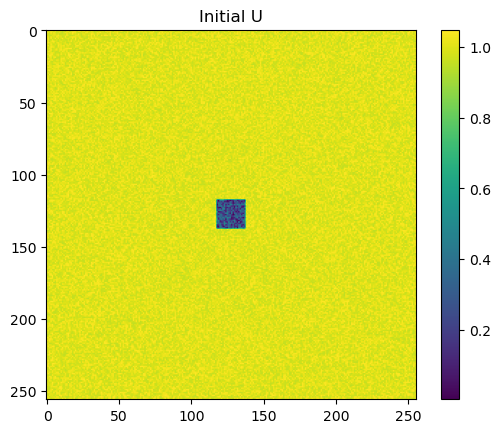

In [8]:
# This code diplays the grid we set in the previous code chunk 
plt.imshow(U, cmap="viridis")
plt.colorbar()
plt.title("Initial U")
plt.show()

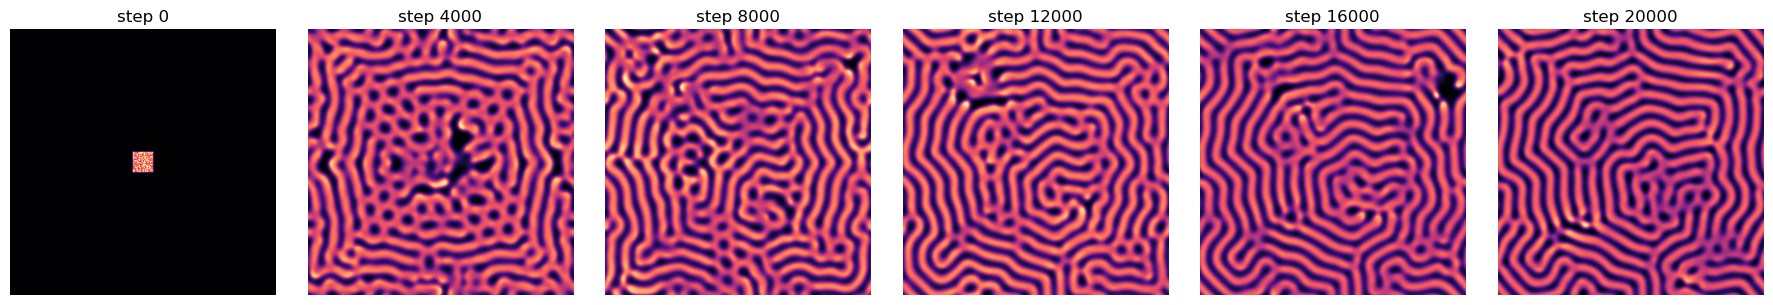

V range: 0.018596936451012673 0.3858433362798148


In [9]:

## Laplacian function that calculates the average concentration of a cell's neigbours 
            
import numpy as np
from scipy.ndimage import convolve #

# 5 point stencil for the laplacian
stencil5 = np.array([[0,  1, 0],
                    [1, -4, 1],
                    [0,  1, 0]])


def laplacian(Z):
    return convolve(Z, stencil5, mode='wrap')  # laplacian 
## Forward Euler Integration
def step(U, V):
    
    lapU = laplacian(U)
    lapV = laplacian(V)
    uvv = U * V * V                      # the reaction term UV^2, computed once

    U_new = U + dt * (Du * lapU - uvv + F * (1 - U))
    V_new = V + dt * (Dv * lapV + uvv - (F + k) * V)
    return U_new, V_new


# Simulate 20000 times, with a snapshot of the system for every 4000 steps 
n_steps = 20000
snap_every = 4000 # Snapshot interval
snapshots = []

for i in range(n_steps + 1):
    if i % snap_every == 0: ## Is this a multiple of 4000?
        snapshots.append((i, V.copy())) ## Append this figure to the list of snapshots
    U, V = step(U, V) ## Move to the next step in the integration


 
## Code for making figures 
fig, axes = plt.subplots(1, len(snapshots), figsize=(3 * len(snapshots), 3))
for ax, (i, snap) in zip(axes, snapshots):
    ax.imshow(snap, cmap="magma")
    ax.set_title(f"step {i}")
    ax.axis("off")
plt.tight_layout()
plt.show()

print("V range:", V.min(), V.max())

F = 0.010 done  (30 s)
F = 0.022 done  (59 s)
F = 0.034 done  (89 s)
F = 0.046 done  (118 s)
F = 0.058 done  (149 s)
F = 0.070 done  (178 s)


/opt/anaconda3/lib/python3.12/site-packages/matplotlib/image.py:500: RuntimeWarning: overflow encountered in divide
  vrange /= ((a_max - a_min) / frac)


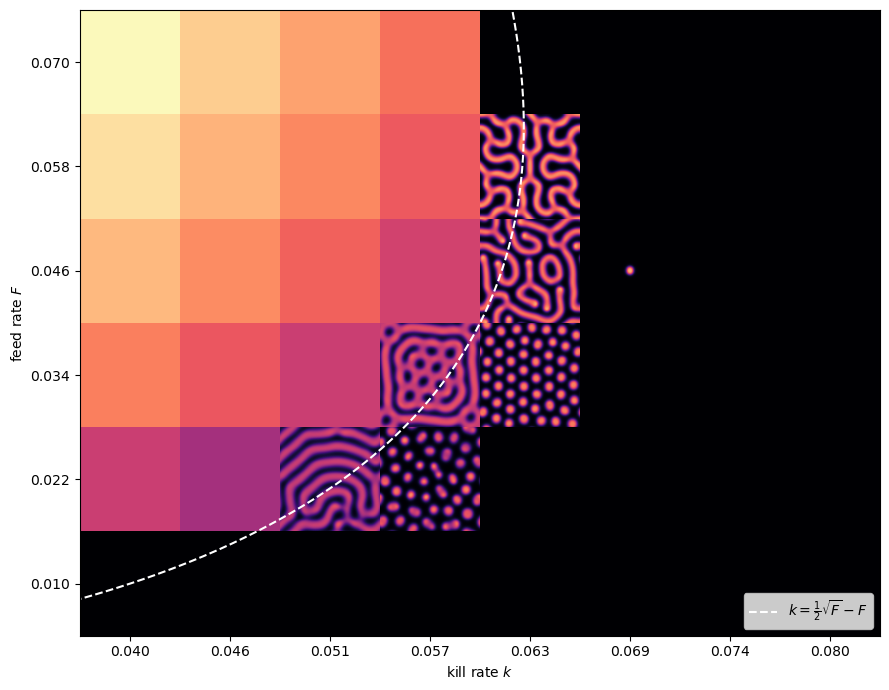

In [6]:
## ---- Parameter map (Pearson's method, shortened) ----
import time
import numpy as np
import matplotlib.pyplot as plt

GRID_SIZE = 96          # grid size for the map (smaller than Pearson's 256)
step_size = 15000   # Step size for euler integration 

## Simulates the Gray Scott model with chosen paramters using Pearson's Method
def simulate(F, k, n=GRID_SIZE, n_steps=step_size, seed=0):
    rng = np.random.default_rng(seed)
    U = np.ones((n, n)) ## Iniitally U has full concentration everywhere 
    V = np.zeros((n, n)) ## No V in the system
    c, h = n // 2, 5                                    
    Du, Dv, dt = 0.2, 0.1, 1.0
    
    center_square = (slice(c - h, c + h), slice(c - h, c + h)) # 10 x 10 central square in the grid
    U[center_square], V[center_square] = 0.5, 0.25 # 
    U *= rng.uniform(0.99, 1.01, size=(n, n))          # vary concentraiton of U and V in the grid by + or - 1 percent
    V *= rng.uniform(0.99, 1.01, size=(n, n))
    for _ in range(n_steps):
        uvv = U * V * V
        U = U + dt * (Du * laplacian(U) - uvv + F * (1 - U))
        V = V + dt * (Dv * laplacian(V) + uvv - (F + k) * V)
    return V

## Creates a grid of (F, k) values 
k_values = np.linspace(0.04, 0.08, 8)
F_values = np.linspace(0.01, 0.07, 6) 

## Run every combination, keeping the final V grid of each
results = {} ## a dictionary containing the final V values for each (F, k) pair
t0 = time.time() 
for F_ in F_values:
    for k_ in k_values:
        results[(F_, k_)] = simulate(F_, k_)
    print(f"F = {F_:.3f} done  ({time.time() - t0:.0f} s)") ## Debug code 


## Figure related code that I didn't write 
np.savez("figures/parameter_map_data.npz",
         F=F_values, k=k_values,
         V=np.array([[results[(F_, k_)] for k_ in k_values] for F_ in F_values]))

## Draw all tiles on one set of axes, using real (k, F) coordinates
dk, dF = k_values[1] - k_values[0], F_values[1] - F_values[0]
fig, ax = plt.subplots(figsize=(9, 7))
for (F_, k_), V_ in results.items():
    ax.imshow(V_, cmap="magma", vmin=0, vmax=0.5, origin="lower",
              extent=[k_ - dk / 2, k_ + dk / 2, F_ - dF / 2, F_ + dF / 2],
              aspect="auto")

## Stability analysis: non-trivial steady states exist only for k <= sqrt(F)/2 - F
F_line = np.linspace(F_values[0] - dF / 2, F_values[-1] + dF / 2, 300) 
ax.plot(0.5 * np.sqrt(F_line) - F_line, F_line, "w--", lw=1.5,
        label=r"$k = \frac{1}{2}\sqrt{F} - F$")

ax.set_xlim(k_values[0] - dk / 2, k_values[-1] + dk / 2)
ax.set_ylim(F_values[0] - dF / 2, F_values[-1] + dF / 2)
ax.set_xticks(k_values); ax.set_xticklabels([f"{x:.3f}" for x in k_values])
ax.set_yticks(F_values); ax.set_yticklabels([f"{x:.3f}" for x in F_values])
ax.set_xlabel("kill rate $k$"); ax.set_ylabel("feed rate $F$")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/parameter_map.png", dpi=200)
plt.show()
